Logistic Regression for Classification

In [ ]:
# If you want to enable matplotlib's interactive features
# install jupyter-matplotlib (a.k.a. ipympl) via pip or conda.
! pip install ipympl --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 511.6/511.6 kB 6.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 36.2 MB/s eta 0:00:00


Restart runtime to continue. Upload the *lab4_utils.py* file to the virtual machine.

In [ ]:
from google.colab import output
output.enable_custom_widget_manager()

# Enable the widget backend.

%matplotlib widget

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt

plt.style.use('seaborn-white')

import pandas as pd
import numpy as np

from lab4_utils import plt_logistic_squared_error, plt_logistic_cost, plt_quad_logistic

%config InlineBackend.figure_format="retina"

<ipython-input-16-eeac64513cb8>:4: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-white')


## Sigmoid or Logistic Function

For a binary classification task, we can start by using our linear regression model, $f_{\mathbf{w},b}(\mathbf{x}^{(i)}) = \mathbf{w} \cdot  \mathbf{x}^{(i)} + b$, to predict $y$ given $\mathbf{x}^{(i)}$.
- However, we would like the predictions of our classification model to be between 0 and 1 since our output variable $y$ is either 0 or 1.
- This can be accomplished by using a "sigmoid function" which maps all input values to values between 0 and 1.


## Formula for Sigmoid function

The formula for a sigmoid function is as follows -  

$\sigma(z) = \frac{1}{1+e^{-z}}\tag{1}$

In [ ]:
def sigmoid(z):

    sigma = 1 / (1 + np.exp(-z))
    return sigma


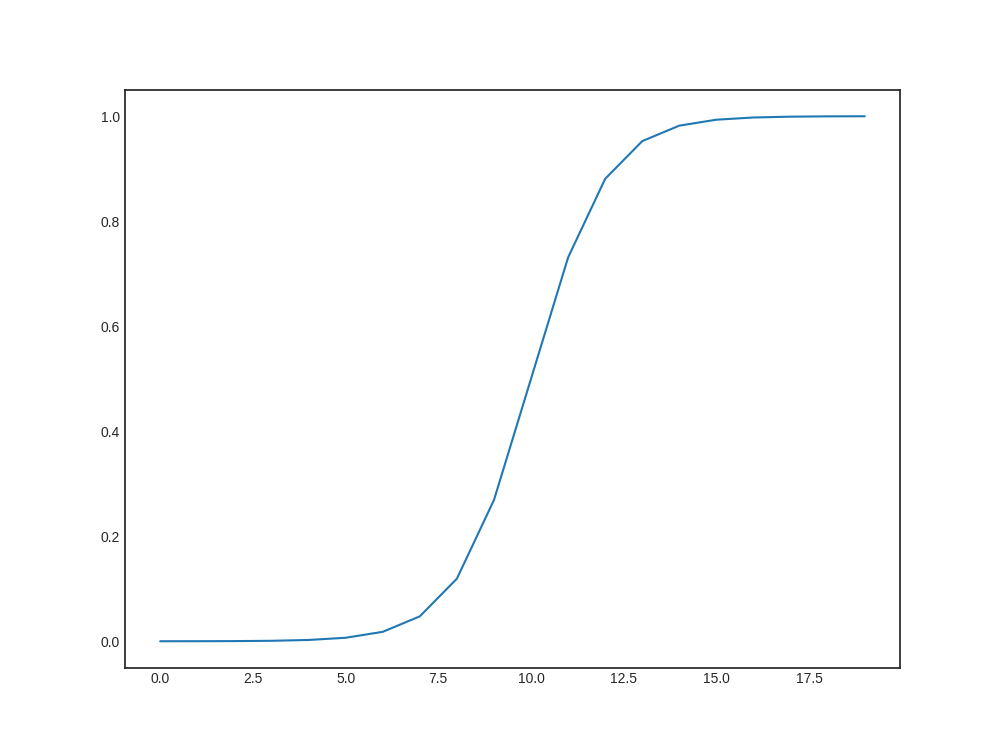

In [ ]:
plt.clf()
plt.subplot()
plt.plot(sigmoid(np.arange(-10, 10)))
plt.show()

## Logistic Regression

A logistic regression model applies the sigmoid to the familiar linear regression model as shown below:

$$ f_{\mathbf{w},b}(\mathbf{x}^{(i)}) = \sigma(\mathbf{w} \cdot \mathbf{x}^{(i)} + b ) \tag{2} $$

  where

  $\sigma(z) = \frac{1}{1+e^{-z}}\tag{3}$

Let's apply logistic regression to the categorical data example of tumor classification.  


In [ ]:
# a one-feature training set
x_train_1 = np.array([0, 1, 2, 3, 4, 5])
y_train_1 = np.array([0, 0, 0, 1, 1, 1])

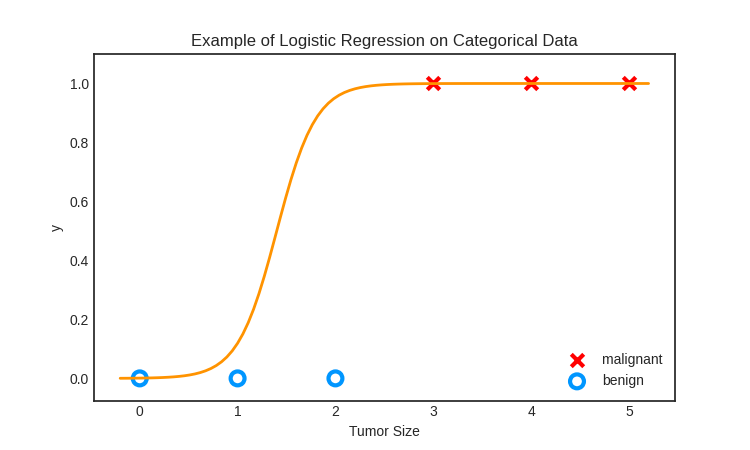

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(7.5, 4.5))
# the initial values for w and b
w, b = 5, -7

ax.scatter(x_train_1[y_train_1 == 1], y_train_1[y_train_1 == 1], marker='x', s=80, c='red', label="malignant", lw=3)
ax.scatter(x_train_1[y_train_1 == 0], y_train_1[y_train_1 == 0], marker='o', s=100, label="benign",
           facecolors='none', edgecolors='#0096ff', lw=3)
ax.set(ylim=[-0.075, 1.1], ylabel='y', xlabel='Tumor Size')

# color code = FF9300
# y_train_1 = sigmoid(w * x_train_1 + b)

x_grid = np.linspace(0-0.2, 5 + 0.2, 100)

# plot garis
ax.plot(x_grid, sigmoid(x_grid*w+b), color="#FF9300", lw=2)

ax.legend(loc='lower right')
ax.set_title("Example of Logistic Regression on Categorical Data")

plt.show()

Using squared error to form the overall cost function for logistic regression leads to a non-convex cost function:



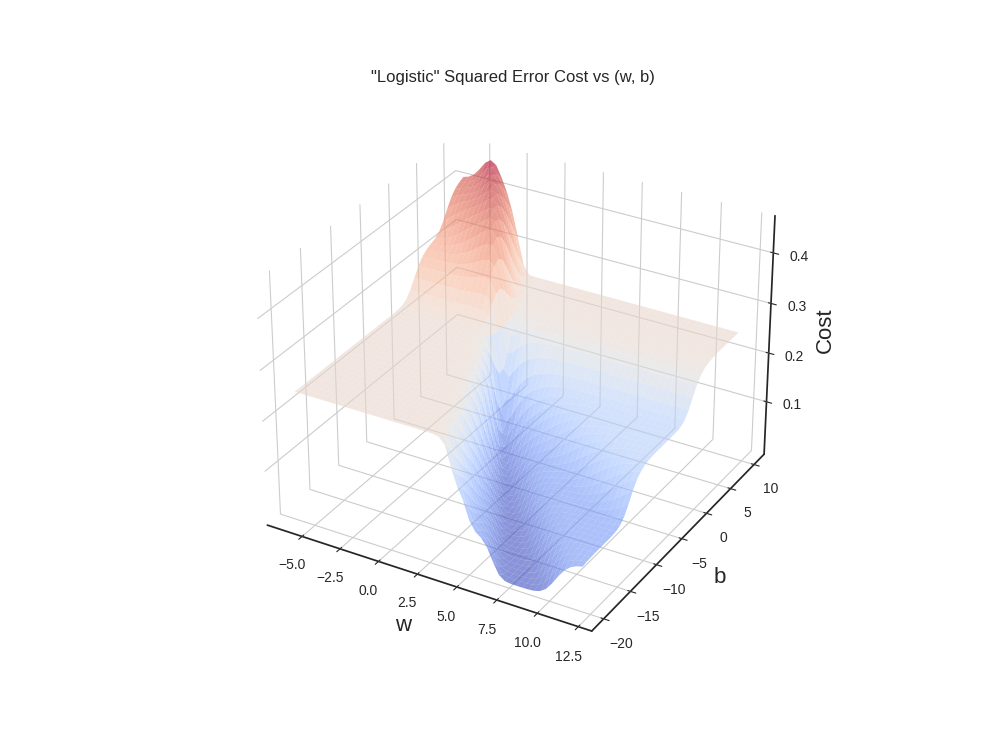

In [ ]:
plt_logistic_squared_error(x_train_1, y_train_1)
plt.show()

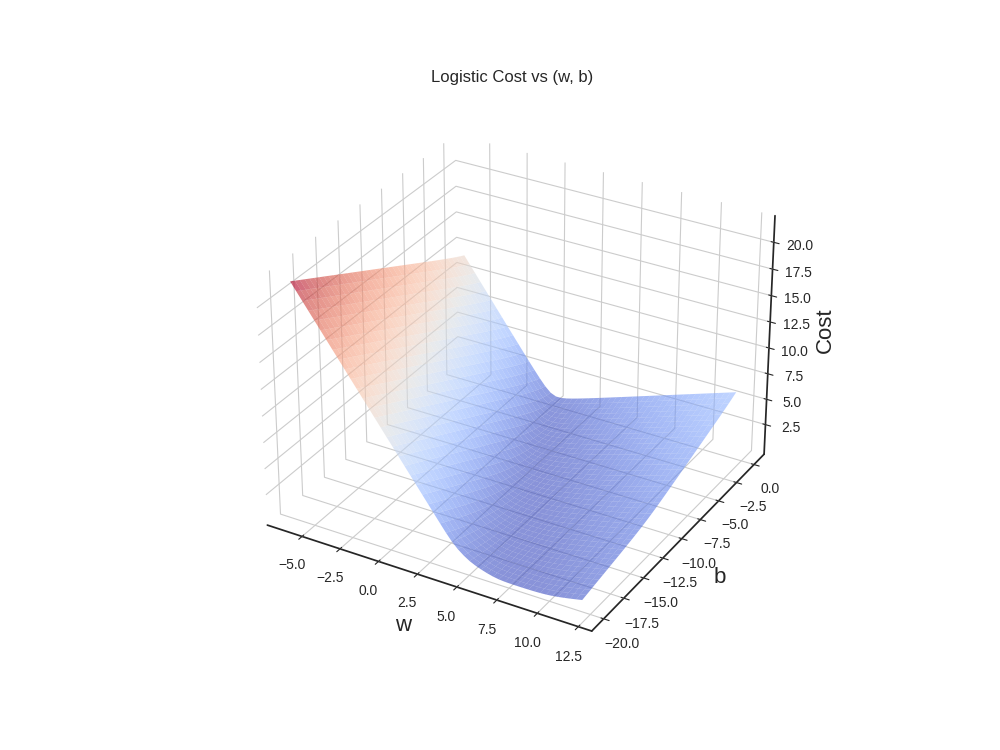

In [ ]:
plt_logistic_cost(x_train_1, y_train_1)
plt.show()

This curve is well suited to gradient descent. It does not have plateaus, local minima, or discontinuities.

In [ ]:
def compute_cost_logistic(X, y, w, b):
  y_hat = sigmoid( (X * w).sum(axis=1) + b)
  cost =  (-y * np.log(y_hat) - (1-y) * np.log(1-y_hat)).mean()
  return cost


In [ ]:
# a two-feature training set
X_train_2 = np.array([[0.5, 1.5], [1, 1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])
y_train_2 = np.array([0, 0, 0, 1, 1, 1])
w_tmp = np.array([1, 1])
b_tmp = -3
print(compute_cost_logistic(X_train_2, y_train_2, w_tmp, b_tmp))

0.36686678640551745


**Expected output**: 0.3668667864055175

## Decision Boundary


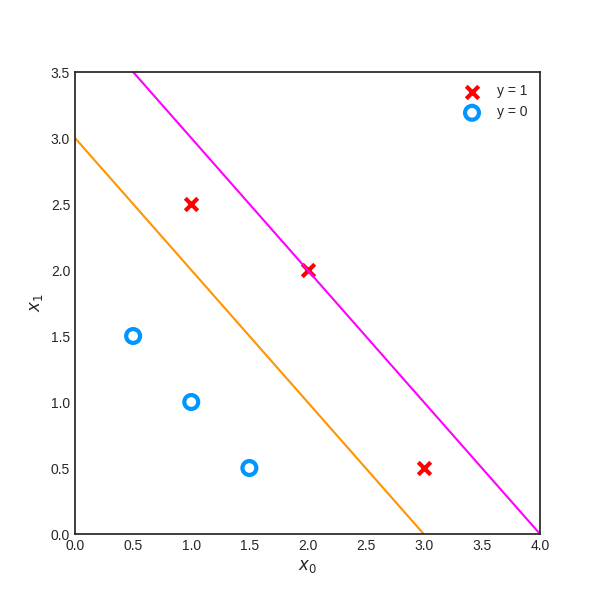

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(6, 6))

# find indices of Positive and Negative Examples
pos = y_train_2 == 1
neg = y_train_2 == 0
# work with 1D or 1D y vectors
pos = pos.reshape(-1,)
neg = neg.reshape(-1,)

ax.scatter(X_train_2[pos, 0], X_train_2[pos, 1], marker='x', s=80, c = 'red', label="y = 1", lw=3)
ax.scatter(X_train_2[neg, 0], X_train_2[neg, 1], marker='o', s=100, label="y = 0", facecolors='none', edgecolors='#0096ff', lw=3)
ax.legend(loc='best')

x0 = np.arange(0, 6)
ax.plot(x0, 3-x0, c='#FF9300', label="$b$=-3")
ax.plot(x0, 4-x0, c='magenta', label="$b$=-4")


# set both axes to be from 0-4
ax.axis([0, 4, 0, 3.5])
ax.set_ylabel('$x_1$', fontsize=12)
ax.set_xlabel('$x_0$', fontsize=12)
plt.show()

## Gradient Descent

In the plot:

- changing $w$ and $b$ by clicking within the contour plot on the upper right.
    - changes may take a second or two
    - note the changing value of cost on the upper left plot.
    - note the cost is accumulated by a loss on each example (vertical dotted lines)
- run gradient descent by clicking the orange button.
    - note the steadily decreasing cost
    - clicking in the contour plot will reset the model for a new run
- to reset the plot, rerun the cell

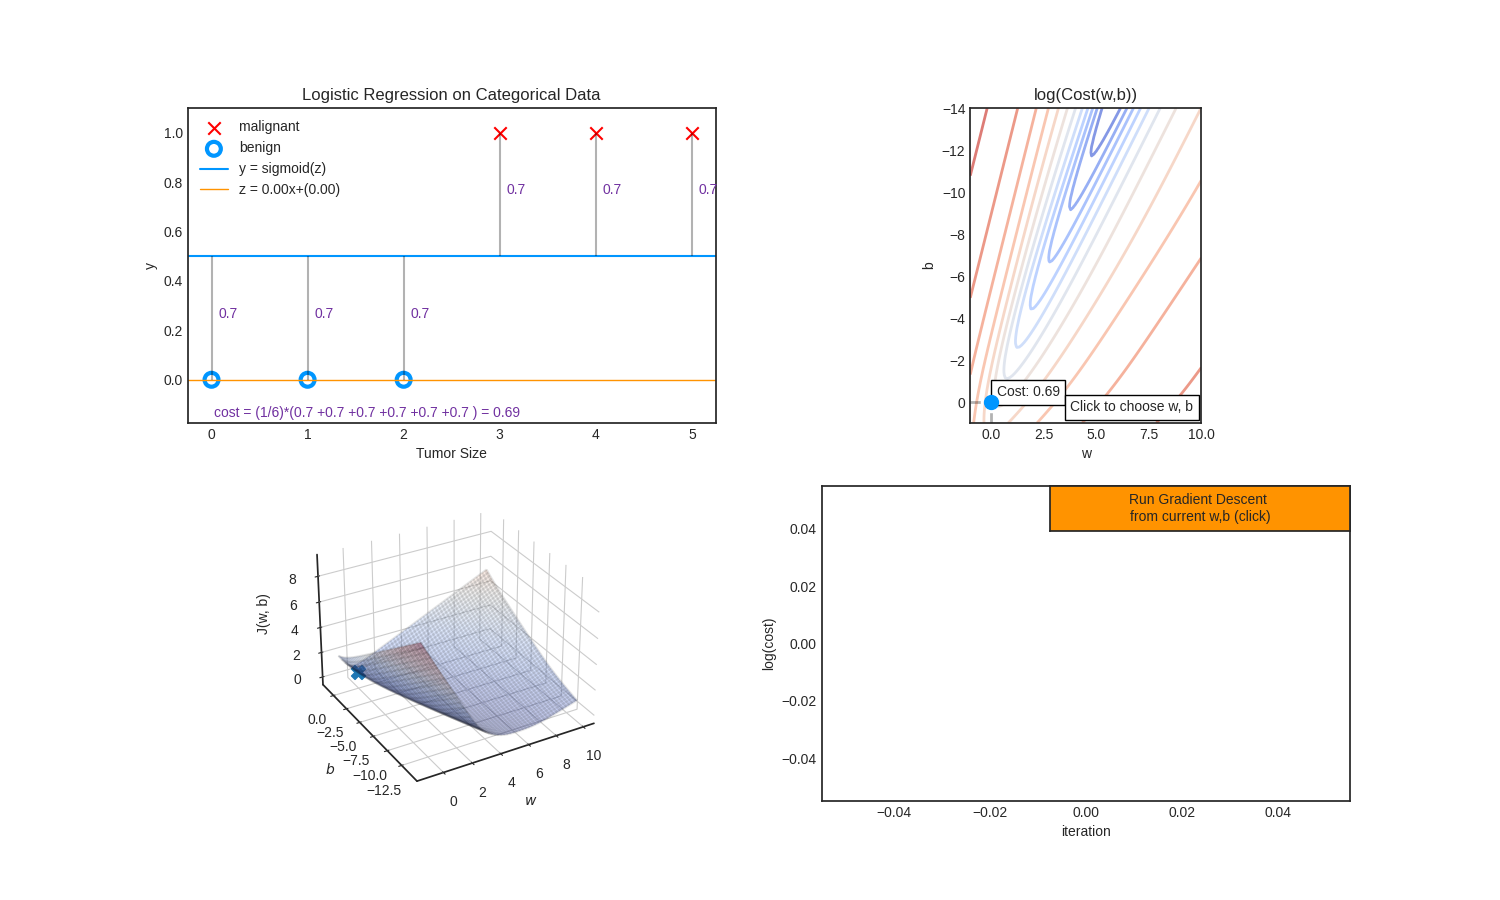

In [ ]:
w_range = np.array([-1, 10])
b_range = np.array([1, -14])
plt.close("all")
quad = plt_quad_logistic(x_train_1, y_train_1, w_range, b_range)